In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("../data/raw/bank-additional-full.csv")
df.head() # important pour vérifier que le fichier a bien été chargé et que les colonnes sont correctes
df.shape # rappel : renvoyer le nombre de lignes et de colonnes du DataFrame
#df.info()


(11162, 17)

On va s'interesser a la distributiuon des ages dans la banque

In [7]:
df["age"].describe()

count    11162.000000
mean        41.231948
std         11.913369
min         18.000000
25%         32.000000
50%         39.000000
75%         49.000000
max         95.000000
Name: age, dtype: float64

Ok on realise un graphique pour mieux visualiser

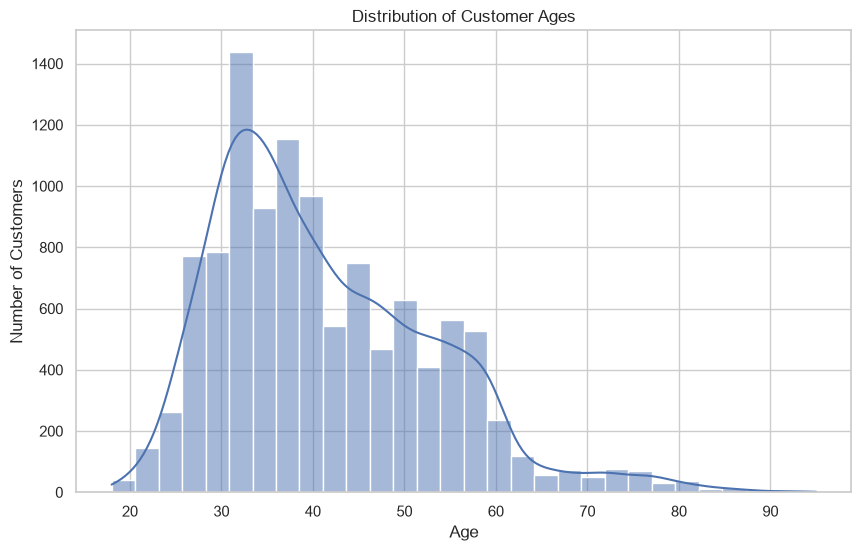

In [9]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

Parrallele aux querys et mon avis : on avait un fort subscription rate des retired mais on remarque qu'ils sont surement peu vu la distribution des ages, a voir par la suite comment ca evolue mais on peut garder cette reflexion dans un coin. Pareil pour les students.

La tranche d'age la plus representee est 30-40 ans. Et la distribtion semble etalee entre 30 et 60ans. Il faut donc aussi prendre en compte le fait qu'un taux élevé calculé sur 30 clients n'a pas la même robustesse qu'un taux élevé calculé sur 1 000 clients.

On va maintenant regarder quels metiers sont les plus representes en gardant la meme logique que pour la distribution d'age.

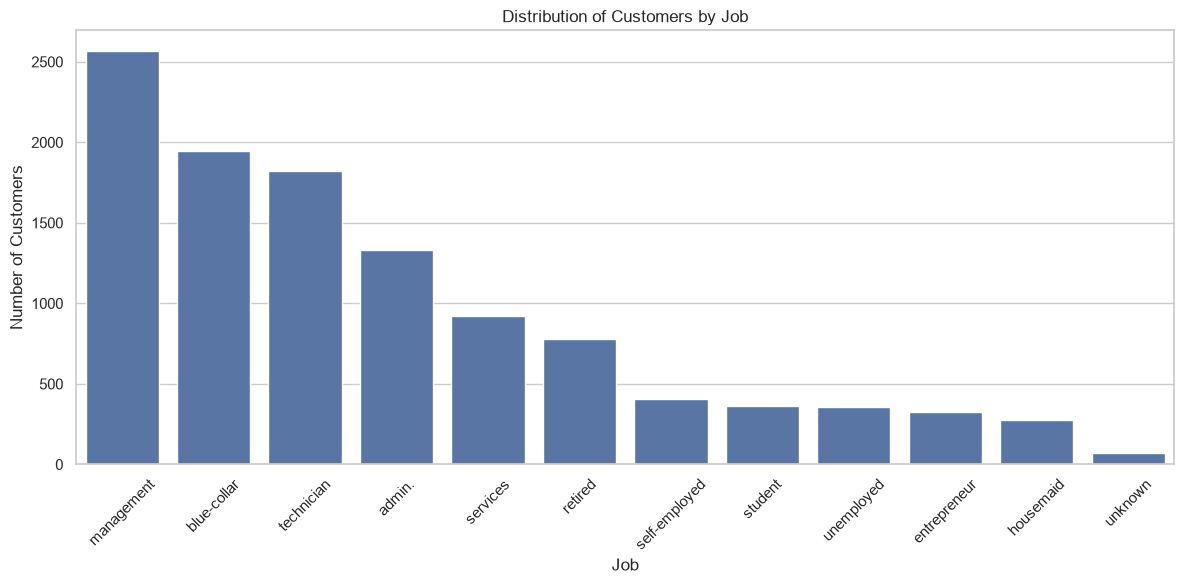

In [10]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="job",
    order=df["job"].value_counts().index
)

plt.title("Distribution of Customers by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Le metier le plus represente est "managment" et de plus de 500 points comparés a la deuxieme categorie. On reste au dessus de 1000 customers pour les metiers suivants : managment, blue-collar, technician et admin.
Hors le unknown, le metier le moins represente est housemaid suivi de entrepreneur.
On remarque d'ailleurs que la population n'est pas vraiment repartie equitablement entre les professions.

Par ailleurs pour faire un rappel avec mon dernier markdown, on remarque qu'en effet les students et retired ne sont pas beaucoup represente, en effet ils se situent dans la deuxieme moitie. 

Comme avec la requete SQL mais cette fois en graphique pour mieux le visualiser, on va regarder si le taux de souscription varie selon l'âge :

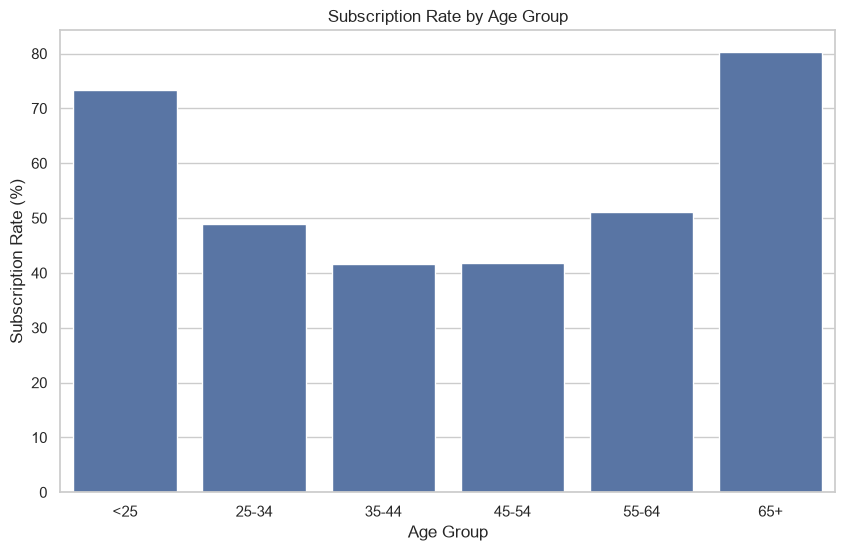

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_subscription.reset_index(),
    x="age_group",
    y="subscription_rate"
)

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

plt.show()

Ici c'est bien plus visuel que notre query, c'est en effet le but de cette EDA.
On remarque bien que les deux plus fortes part d'age sont -25 et +65 ans. Mais meme remarque et note qu'au dessus, ces parties sont sous representeees par rapport aux autres, donc il ne faut pas se laisser biaiser par ces simples informations mais il faut aller chercher plus loin.
D'ailleurs, la part la plus representee dans le DataFrame est 30-40 ans, ici reparti en deux categories, ou le subscription rate est d'environ 40%.
Ca peut paraitre bien moins que les deux autres parts citees au dessus mais on analyse pas la meme quantite de personnes donc c'est normal.

Continuons de voir si les soucriptions varient selon le mois :

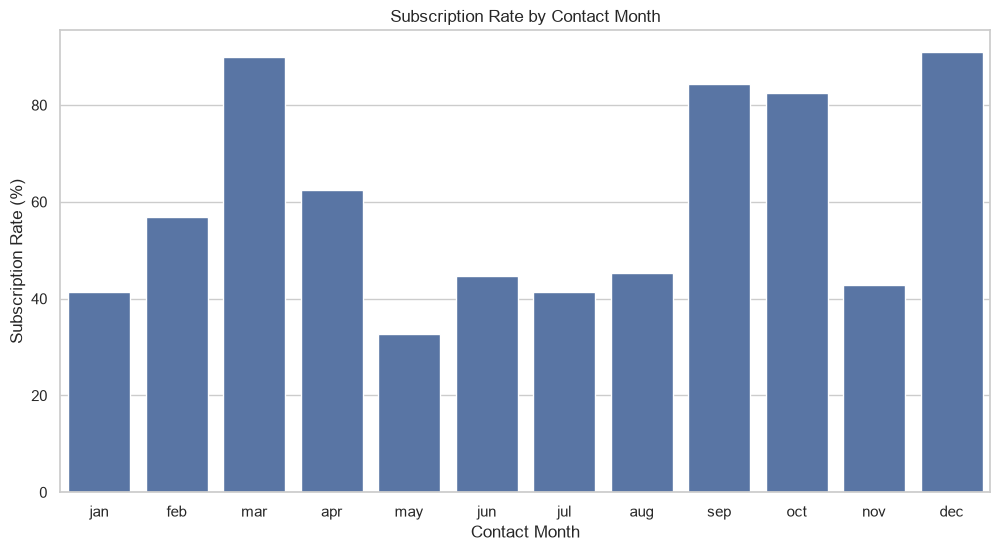

In [16]:
month_order = [
    "jan", "feb", "mar", "apr",
    "may", "jun", "jul", "aug",
    "sep", "oct", "nov", "dec"
]

month_subscription = (
    df.groupby("month", observed=False)
    .agg(
        total_customers=("deposit", "count"),
        subscribed=("deposit", lambda x: (x == "yes").sum())
    )
)

month_subscription["subscription_rate"] = (
    month_subscription["subscribed"]
    / month_subscription["total_customers"] * 100
)

month_subscription = month_subscription.reindex(month_order)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=month_subscription.index,
    y=month_subscription["subscription_rate"]
)

plt.title("Subscription Rate by Contact Month")
plt.xlabel("Contact Month")
plt.ylabel("Subscription Rate (%)")

plt.show()

Ici contrairement aux autres variables, les donnes semblent reparties plutot equitablement. On a quand meme une forte hausse en septembre et octobre, une en decembre et une en mars, la periode a retenir pour ce graphe est Septembre/Octobre a mon avis.

Maintenant on va passer a quelque chose de plus interessant, les possibles correlations entre nos variables, a savoir que :
- Corrélation proche de 1 : relation linéaire positive.
- Corrélation proche de -1 : relation linéaire négative.
- Corrélation proche de 0 : absence de relation linéaire marquée.
Mais attention, corrélation ne signifie pas causalité. Une corrélation proche de zéro n'exclut pas non plus une relation non linéaire.

In [17]:
numeric_df = df.select_dtypes(include=["number"])

correlation_matrix = numeric_df.corr()

correlation_matrix

,age,balance,day,duration,campaign,pdays,previous
age,1.000000,0.112300,-0.000762,0.000189,-0.005278,0.002774,0.020169
balance,0.112300,1.000000,0.010467,0.022436,-0.013894,0.017411,0.030805
day,-0.000762,0.010467,1.000000,-0.018511,0.137007,-0.077232,-0.058981
duration,0.000189,0.022436,-0.018511,1.000000,-0.041557,-0.027392,-0.026716
campaign,-0.005278,-0.013894,0.137007,-0.041557,1.000000,-0.102726,-0.049699
pdays,0.002774,0.017411,-0.077232,-0.027392,-0.102726,1.000000,0.507272
previous,0.020169,0.030805,-0.058981,-0.026716,-0.049699,0.507272,1.000000


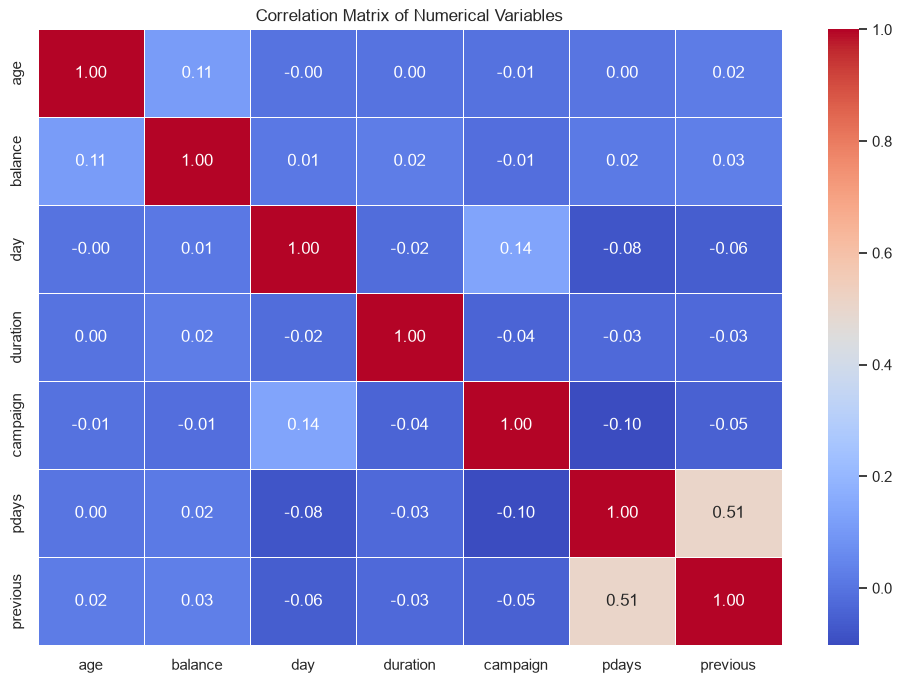

In [18]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")

plt.show()

Interessant, on remarque plusieurs correlations entre : 
age et balance
age et campaign
campaign et previous
Toutes celles ci restent plutot logique, meme pour celle entre pdays et previous.

Pour mieux comprendre cette derniere correlation tres elevee, on peut checker ce qu'il se passe dans nos données:


In [19]:
df.groupby("previous")["pdays"].agg(
    ["count", "mean", "min", "max"]
).head(15)

print("Nombre de clients sans contact précédent :")
print((df["previous"] == 0).sum())

print("\nNombre de clients avec pdays = -1 :")
print((df["pdays"] == -1).sum())

print("\nNombre de clients ayant previous = 0 et pdays = -1 :")
print(((df["previous"] == 0) & (df["pdays"] == -1)).sum())

Nombre de clients sans contact précédent :
8324

Nombre de clients avec pdays = -1 :
8324

Nombre de clients ayant previous = 0 et pdays = -1 :
8324


Voila, on a compris du coup pourquoi cette correlation. En effet 8324 clients n'ont jamais ete contactes lors d'une campgane precedente, ce qui represente
plus de la moitie des clients du dataset et qui implique donc une influence forte dans les resultats finaux. Il etait important de le checker et de constater le probleme au lieu de juste se fier a une forte correlation.
Donc c'est toujours important de comprendre ce qui jsutifie une correlation avant de decider si elle doit influencer notre preprocessing ou notre selection de variables.

Verifions ce qu'il se passe si on supprime les clients qui ont un pdays = -1 dans notre calcul:

In [21]:
contacted_before = df[df["previous"] > 0]

correlation_without_never_contacted = contacted_before[
    ["pdays", "previous"]
].corr()

correlation_without_never_contacted

,pdays,previous
pdays,1.0000,-0.0122
previous,-0.0122,1.0000


Superbe, on voit bien que maintenant, notre correlation est a -0.01, et on a donc bien fait de chercher pourquoi elle etait aussi haute avant de la prendre en compte !

On va maintenant passer a l'analyse des outliers : 

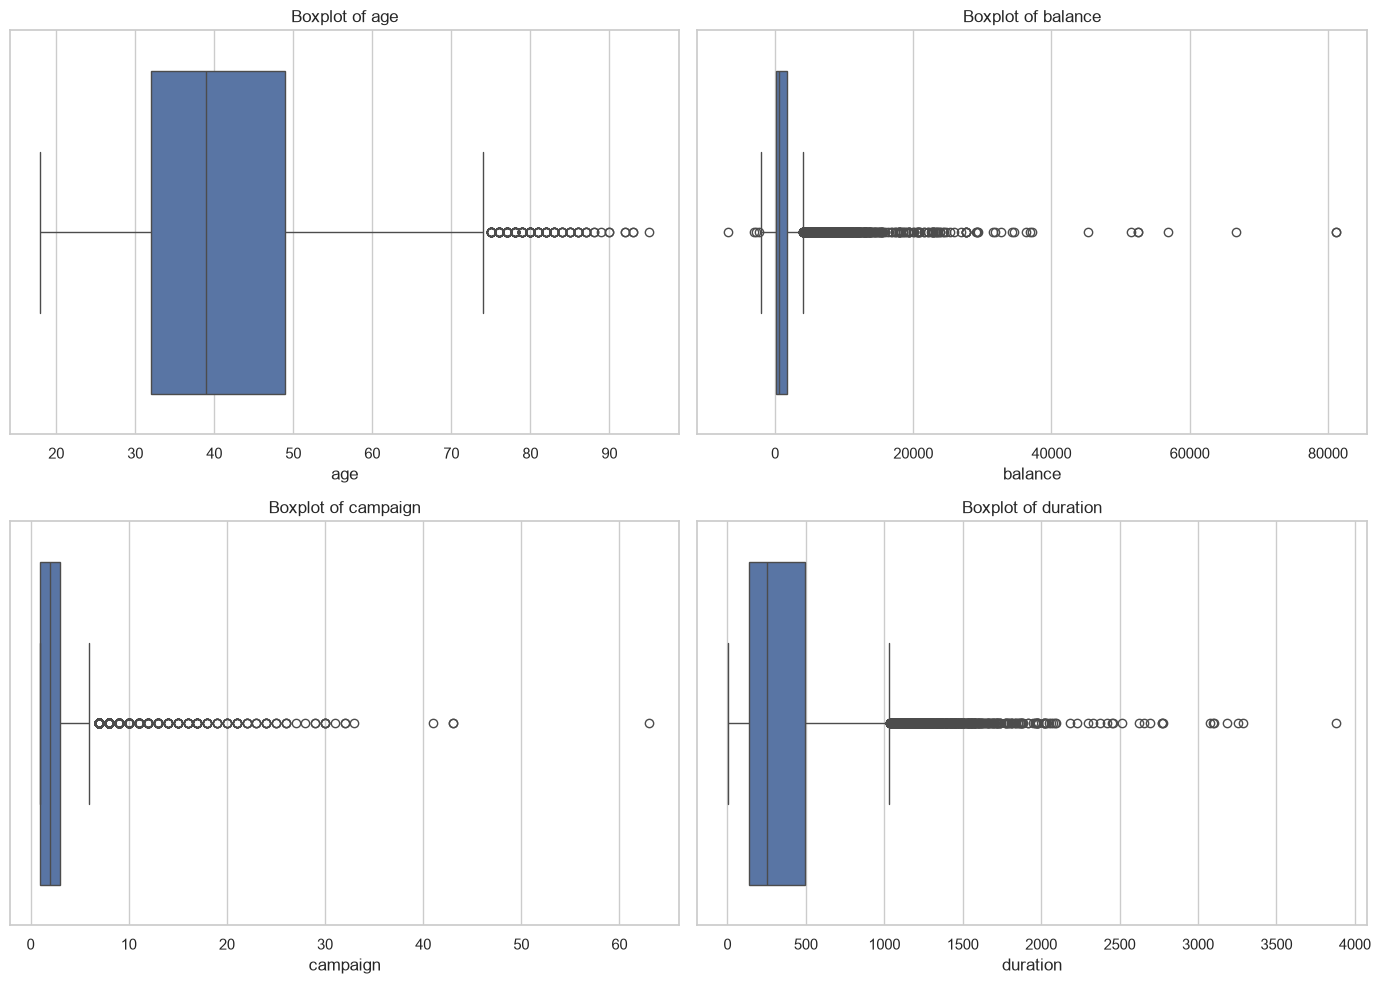

In [22]:
variables = ["age", "balance", "campaign", "duration"]

plt.figure(figsize=(14, 10))

for i, column in enumerate(variables, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x=column)
    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

Ok, ces 4 boxplot nous permettent d'identifier quelques anomalies:
Dans balance, on remarque seulement quelques clients au dessus de 40000$.
Pour campaign, on a 3 clients qui ont ete contacte plus de 40 fois, ce qui parait vraiment tres louche.
Et pour duration, on remarque qu'un appel a dure casiment 4000 secondes, ce qui parait aussi louche. Mais on se rappelle que duration ne doit pas etre pris en compte dans notre modele principal car on ne connait pas sa valeur avant l'appel.
Aussi, il est important de noter que meme si on a un outlier, il faut le prendre en compte, on ne peut pas le supprimer sans justification.

In [23]:
for column in ["age", "balance", "campaign", "duration"]:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of outliers:", len(outliers))
    print("Percentage:", round(len(outliers) / len(df) * 100, 2), "%")


age
Lower bound: 6.5
Upper bound: 74.5
Number of outliers: 171
Percentage: 1.53 %

balance
Lower bound: -2257.0
Upper bound: 4087.0
Number of outliers: 1055
Percentage: 9.45 %

campaign
Lower bound: -2.0
Upper bound: 6.0
Number of outliers: 601
Percentage: 5.38 %

duration
Lower bound: -399.0
Upper bound: 1033.0
Number of outliers: 636
Percentage: 5.7 %


On s'attaque maintenant une partie importante, étudier les relations entre les variables explicatives et notre cible deposit.

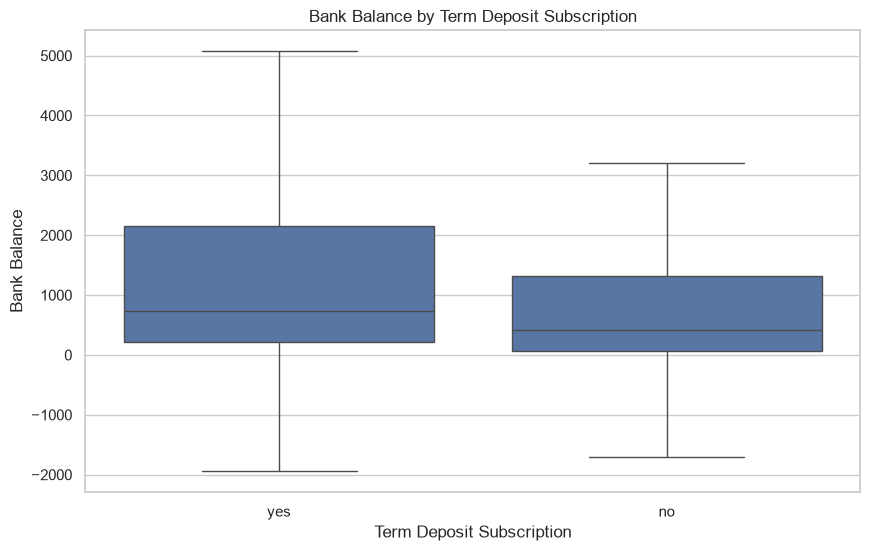

In [24]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="deposit",
    y="balance",
    showfliers=False
)

plt.title("Bank Balance by Term Deposit Subscription")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Bank Balance")

plt.show()

La mediane est plus elevee chez les clients ayant souscrit que chez ceux n'ayant pas souscrit.
Cela signifie que les clients disposant d'un solde bancaire plus eleve pourraient etre davantage susceptible de souscrire.
Mais les deux distributions restent tres proches, on ne peut donc pas affirmer que le solde permette a lui seul de predire la souscription.

On passe a la prochaine valeur :

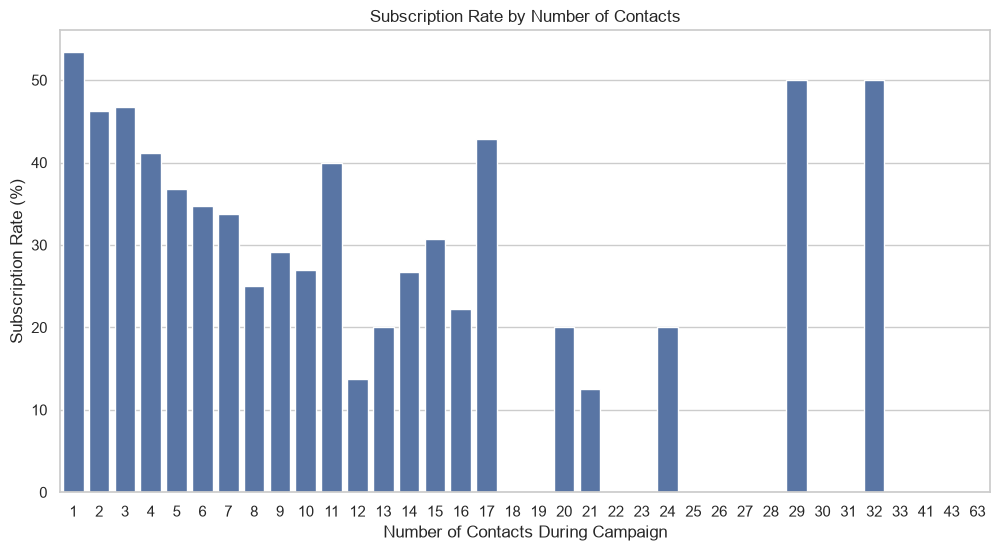

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=campaign_subscription.reset_index(),
    x="campaign",
    y="subscription_rate"
)

plt.title("Subscription Rate by Number of Contacts")
plt.xlabel("Number of Contacts During Campaign")
plt.ylabel("Subscription Rate (%)")

plt.show()

Plutot interessant, on remarque que le nombre de contact qui a le plus haut subscription rate est de 1, hors jusqu'a environ 20, a part pour certaines valurs, le subscription rate ne fait que de diminuer.

On continue avec poutcome, le resultat de la campaign precedente :

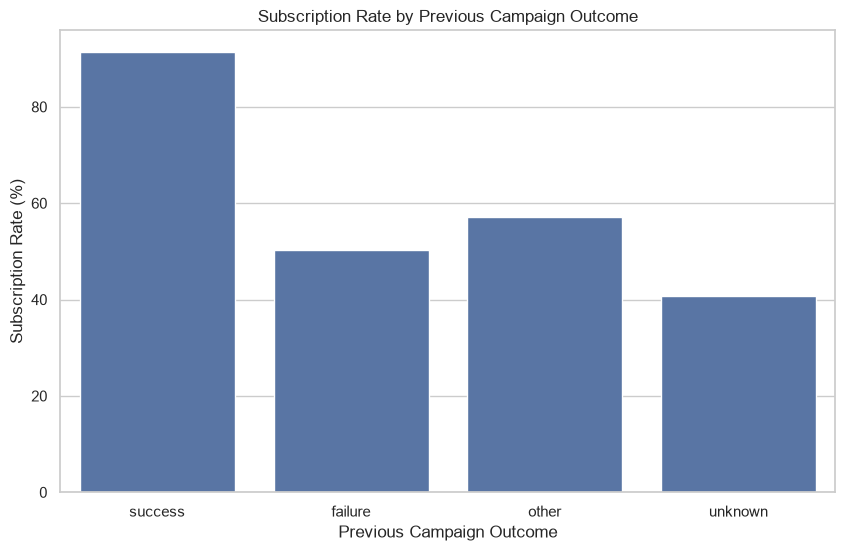

In [29]:
poutcome_subscription = (
    df.groupby("poutcome")
    .agg(
        total_customers=("deposit", "count"),
        subscribed=("deposit", lambda x: (x == "yes").sum())
    )
)

poutcome_subscription["subscription_rate"] = (
    poutcome_subscription["subscribed"]
    / poutcome_subscription["total_customers"] * 100
)

poutcome_subscription

plt.figure(figsize=(10, 6))

sns.barplot(
    data=poutcome_subscription.reset_index(),
    x="poutcome",
    y="subscription_rate",
    order=["success", "failure", "other", "unknown"]
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.show()

Ok, on est ici sur une variable plutot interessante, en effet comme deja repere pendant les querys sql,  le fait qu'un client est souscrit a la derniere campagne augmente enormement son subscription rate ! Failure represente quand a lui un taux plus faible mais non negligeable, 50% environ.
La categorie unknown represente tout de meme 8326 clients, une bonne partie, donc meme si on y voit une correlation. Les effectifs restent quand meme suffisant pour comparer les categories.

On passe maintenant a job :

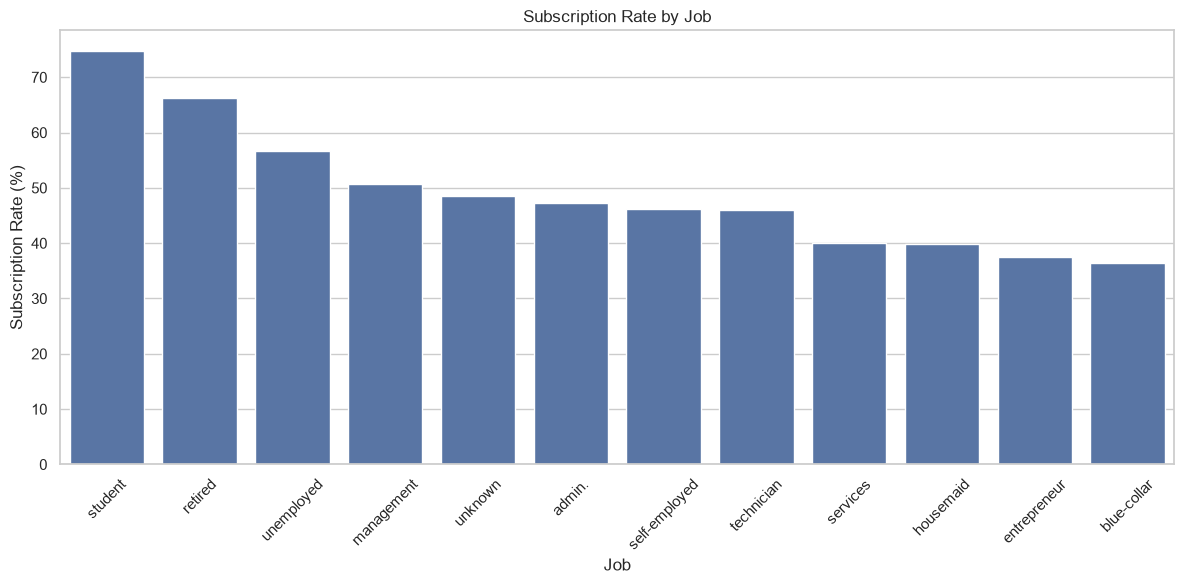

In [30]:
job_subscription = (
    df.groupby("job")
    .agg(
        total_customers=("deposit", "count"),
        subscribed=("deposit", lambda x: (x == "yes").sum())
    )
)

job_subscription["subscription_rate"] = (
    job_subscription["subscribed"]
    / job_subscription["total_customers"] * 100
)

job_subscription = job_subscription.sort_values(
    "subscription_rate", ascending=False
)

job_subscription

plt.figure(figsize=(12, 6))

sns.barplot(
    data=job_subscription.reset_index(),
    x="job",
    y="subscription_rate"
)

plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

meme analyse que sur les querys de sql, mais on garde en tete que ce ne sont pas les categories les plus representee, a noter que managment se situe en 4eme position, sachant que c'est la categorie la plus representee, c'est une information a prendre en compte pour plus tard.

Passons a housing, qui logiquement, devrait etre relie a notre variable cible :

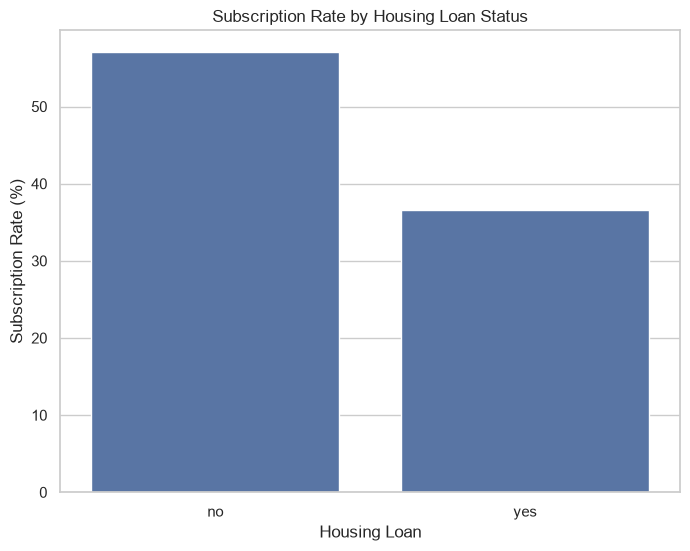

In [31]:
housing_subscription = (
    df.groupby("housing")
    .agg(
        total_customers=("deposit", "count"),
        subscribed=("deposit", lambda x: (x == "yes").sum())
    )
)

housing_subscription["subscription_rate"] = (
    housing_subscription["subscribed"]
    / housing_subscription["total_customers"] * 100
)

housing_subscription

plt.figure(figsize=(8, 6))

sns.barplot(
    data=housing_subscription.reset_index(),
    x="housing",
    y="subscription_rate"
)

plt.title("Subscription Rate by Housing Loan Status")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate (%)")

plt.show()

Comme presume, on voit clairement que les clients ayant un credit immobilier souscrivent moins aux campagnes, ce qui parait logique, cette information reste aussi importante a garder.

On va passer aux autres variables : 

In [32]:
for column in ["loan", "default"]:

    result = (
        df.groupby(column)
        .agg(
            total_customers=("deposit", "count"),
            subscribed=("deposit", lambda x: (x == "yes").sum())
        )
    )

    result["subscription_rate"] = (
        result["subscribed"] / result["total_customers"] * 100
    )

    print(f"\n--- {column.upper()} ---")
    print(result.round(2))

    


--- LOAN ---
      total_customers  subscribed  subscription_rate
loan                                                
no               9702        4805              49.53
yes              1460         484              33.15

--- DEFAULT ---
         total_customers  subscribed  subscription_rate
default                                                
no                 10994        5237              47.64
yes                  168          52              30.95


Un petit peu le meme raisonnement que la variable precedente pour loan, les clients sous credits souscrivent moins. Idem pour default, ce qui est logique aussi, ces deux variables sont donc a prendre en compte pour notre modele.

Pour conclure avec une synthese, on fait un recap de tout ce qu'on a vu pour etre sur de soi.

In [33]:

# ==========================================
# FINAL EDA SUMMARY - DATA COLLECTION
# ==========================================

# 1. Target distribution
print("\n========== TARGET DISTRIBUTION ==========")
print(df["deposit"].value_counts())
print("\nPercentages:")
print((df["deposit"].value_counts(normalize=True) * 100).round(2))


# 2. Subscription rates for categorical variables
categorical_columns = [
    "job", "month", "poutcome",
    "housing", "loan", "default", "marital", "education"
]

print("\n========== CATEGORICAL VARIABLES ==========")

for column in categorical_columns:
    print(f"\n--- {column.upper()} ---")

    result = df.groupby(column).agg(
        total_customers=("deposit", "count"),
        subscribed=("deposit", lambda x: (x == "yes").sum())
    )

    result["subscription_rate"] = (
        result["subscribed"] / result["total_customers"] * 100
    )

    print(result.round(2).sort_values(
        "subscription_rate", ascending=False
    ))


# 3. Age groups
print("\n========== AGE GROUPS ==========")

age_groups = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"],
    right=False
)

age_result = df.groupby(age_groups, observed=False).agg(
    total_customers=("deposit", "count"),
    subscribed=("deposit", lambda x: (x == "yes").sum())
)

age_result["subscription_rate"] = (
    age_result["subscribed"] / age_result["total_customers"] * 100
)

print(age_result.round(2))


# 4. Numerical variables by target
print("\n========== NUMERICAL VARIABLES BY DEPOSIT ==========")

for column in ["age", "balance", "campaign", "duration",
               "pdays", "previous"]:
    print(f"\n--- {column.upper()} ---")
    print(
        df.groupby("deposit")[column]
        .agg(["mean", "median", "std"])
        .round(2)
    )


# 5. Missing values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


# 6. Dataset dimensions
print("\n========== DATASET ==========")
print("Shape:", df.shape)



========== TARGET DISTRIBUTION ==========
deposit
no     5873
yes    5289
Name: count, dtype: int64

Percentages:
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64

========== CATEGORICAL VARIABLES ==========

--- JOB ---
               total_customers  subscribed  subscription_rate
job                                                          
student                    360         269              74.72
retired                    778         516              66.32
unemployed                 357         202              56.58
management                2566        1301              50.70
unknown                     70          34              48.57
admin.                    1334         631              47.30
self-employed              405         187              46.17
technician                1823         840              46.08
services                   923         369              39.98
housemaid                  274         109              39.78
entrepreneur    

La conclusion suivante est faite par IA pour gagner du temps sur des micro syntheses et graphes deja etudiés auparavant. Elle a été lue entierement et vérifiée avec les informations deja inscrites dans les markdowns presents sur ce notebook.
Cette conclusion permet juste de regrouper les infos recuperees a travers ce notebook pour que tout soit plus clair et au bon endroit.

## 3. Synthese de l'analyse exploratoire (EDA)

L'analyse exploratoire a permis de mieux comprendre les caracteristiques des clients et les facteurs associes a la souscription d'un depot a terme.

Le dataset contient **11 162 observations et 18 colonnes**, dont la variable cible `deposit`. Les deux classes sont relativement equilibrees : 52.62 % de clients n'ont pas souscrit, contre 47.38 % qui ont souscrit. Aucune valeur manquante n'a ete detectee.

Plusieurs tendances se degagent :

- **Profil client :** les etudiants (74.72 %), les retraites (66.32 %) et les clients de moins de 25 ans ou de 65 ans et plus presentent des taux de souscription eleves.
- **Periode de contact :** les taux les plus eleves sont observes en mars, septembre et octobre. Le mois de mai presente le taux le plus faible (32.75 %).
- **Historique marketing :** les clients dont la campagne precedente s'est terminee par un succes affichent un taux de souscription de 91.32 %.
- **Situation financiere :** les clients sans credit immobilier ou personnel presentent des taux de souscription plus eleves.
- **Comportement de campagne :** les clients ayant souscrit ont en moyenne ete contactes moins souvent pendant la campagne actuelle (2.14 contre 2.84 contacts).

L'analyse a egalement mis en evidence des valeurs extremes dans certaines variables numeriques, ainsi qu'un encodage particulier de `pdays` : la valeur `-1` indique l'absence de contact lors d'une campagne precedente.

Enfin, la variable `duration` presente une relation importante avec la souscription, mais elle sera exclue du modele principal : sa valeur n'est connue qu'a la fin de l'appel et ne serait donc pas disponible pour une prediction realisee avant le contact.

### Conclusion

Le dataset presente une qualite globale satisfaisante pour poursuivre le projet. Plusieurs variables semblent apporter une information interessante pour predire la souscription, mais ces relations restent descriptives et ne prouvent pas un lien de causalite.

La prochaine etape consiste a preparer les donnees pour la modelisation : traitement des variables categorielles, selection des variables, separation des jeux d'entrainement et de test, puis entrainement des premiers modeles de classification.